# Walkthrough of the skip-prediction project (ES 335)

This notebook does **not** train anything. It loads the result files written by the scripts in `python/` and walks through the steps in order, so a reader can check the numbers without waiting for the long tuning run.

Run it from the project root or from `notebooks/`. To re-create the results themselves, run the scripts listed in the README.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd() if (Path.cwd() / 'python').exists() else Path.cwd().parent
R = lambda step: ROOT / 'python' / step / 'results'
load = lambda step, name: json.loads((R(step) / name).read_text())
pd.set_option('display.precision', 4)

## 1. Data understanding (`python/01_data_understanding/analyze.py`)

Top-level keys: ['schema_version', 'generated_at', 'title', 'status', 'scope', 'paths', 'sources', 'access_limits', 'size', 'tables', 'join', 'important_variables']


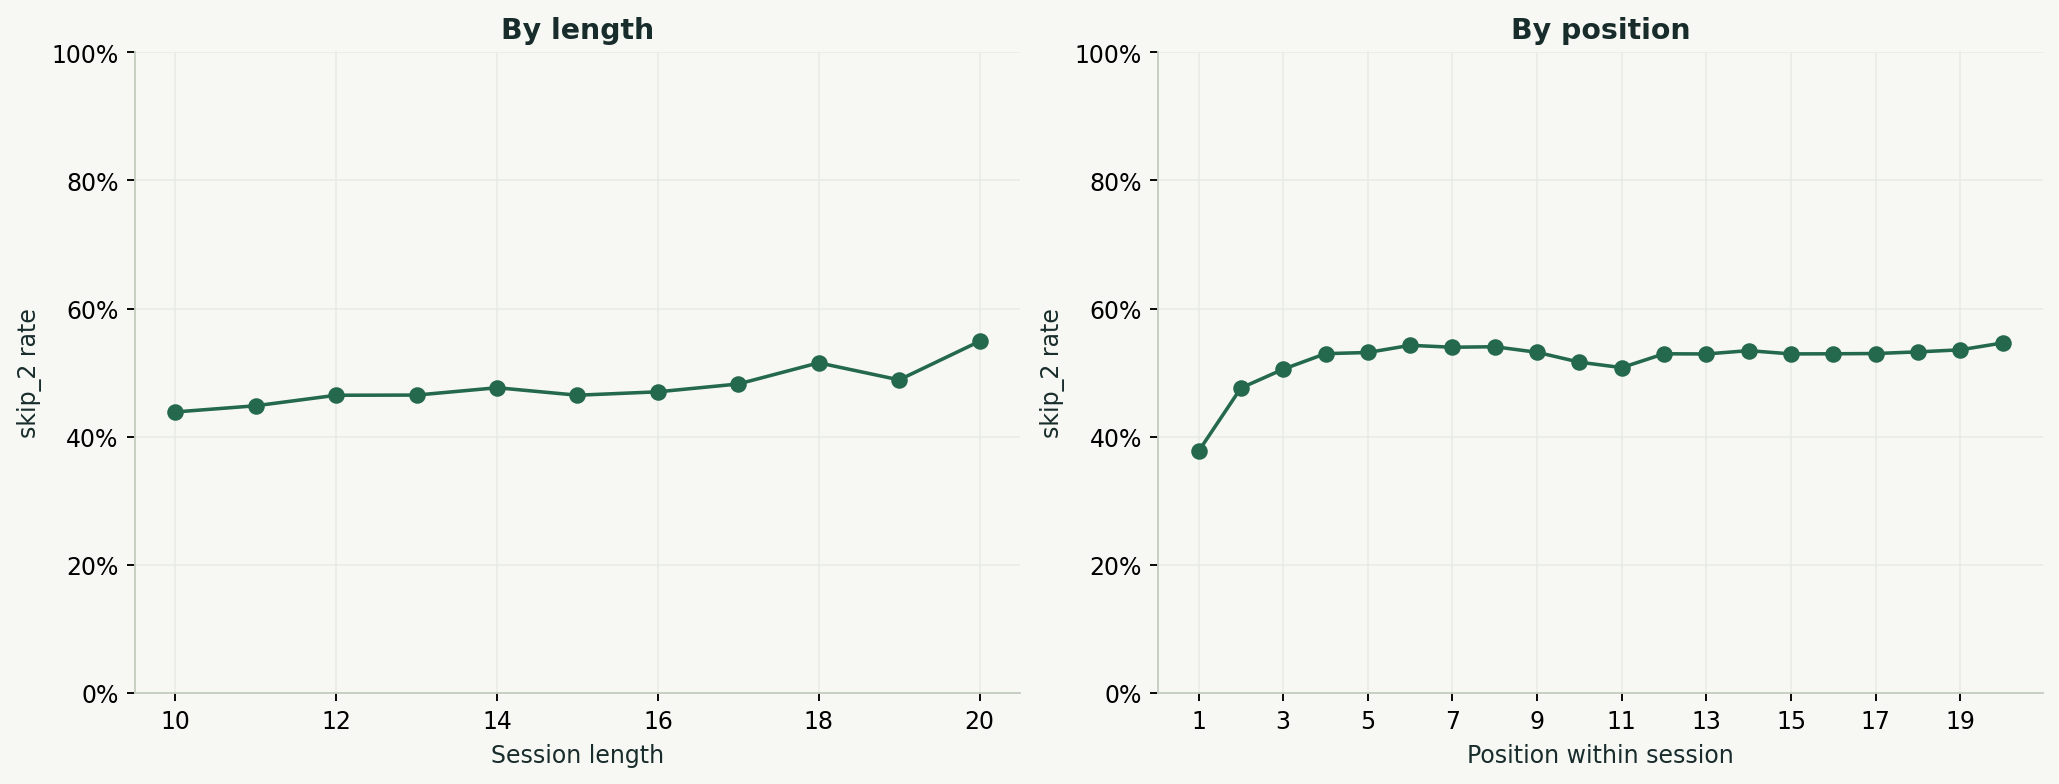

In [2]:
du = load('01_data_understanding', 'data_understanding.json')
print('Top-level keys:', list(du)[:12])
display(Image(filename=str(R('01_data_understanding') / 'images' / 'skip_rates.png'), width=600))

## 2. Split and features (`python/02_preprocessing`)
The split is by session (seed 42). The first ceil(L/2) songs are the history; the rest are predicted.

In [3]:
fs = load('02_preprocessing', 'feature_summary.json')
print('sessions:', fs['sessions'], '\nrows:', fs['rows'], '\nfeatures:', fs['feature_count'])
pd.DataFrame({g: {'name': v['name'], 'columns': v['count']} for g, v in fs['groups'].items()}).T

sessions: {'development': 8000, 'test': 2000, 'total': 10000} 
rows: {'development': 66183, 'test': 16573, 'total': 82756} 
features: 91


,name,columns
P,Popularity,1
H,Listening history and queue position,55
A,Track audio and metadata,28
S,Similarity to the session's own history,7


## 3. Tuning on development sessions only (`python/03_tuning/run_experiments.py`)
Every model below was chosen on 15 session-grouped folds of the development sessions.

In [4]:
dev = load('03_tuning', 'development.json')
pd.DataFrame({k: {'dev MAA (15 folds)': v['mean_fold_maa'], 'fold SD': v['std_fold_maa'], 'AUC': v['roc_auc']} for k, v in dev['selected'].items()}).T.sort_values('dev MAA (15 folds)')

,dev MAA (15 folds),fold SD,AUC
global_majority,0.4092,0.0038,0.5000
popularity_lr,0.4092,0.0038,0.5097
history_majority,0.5132,0.0063,0.6189
copy_last,0.5380,0.0050,0.6288
history_lr,0.5650,0.0039,0.7100
random_forest,0.5743,0.0061,0.7331
lightgbm,0.5823,0.0055,0.7446
catboost,0.5824,0.0059,0.7443
xgboost,0.5828,0.0060,0.7447


In [5]:
print('primary model:', dev['primary'], '| threshold:', dev['threshold'])
pd.DataFrame(dev['ablation'])[['groups', 'features', 'mean_fold_maa', 'std_fold_maa', 'roc_auc']]

primary model: lightgbm | threshold: 0.5


,groups,features,mean_fold_maa,std_fold_maa,roc_auc
0,P,1,0.3740,0.0047,0.5158
1,H,55,0.5821,0.0056,0.7416
2,PH,56,0.5827,0.0056,0.7430
3,PHA,84,0.5813,0.0055,0.7427
4,PHS,63,0.5828,0.0061,0.7451
5,PHAS,91,0.5823,0.0055,0.7446


## 4. Final test, scored once (`python/04_final_test/run_final.py`)

In [6]:
test = load('04_final_test', 'test_results.json')
t = pd.DataFrame([{'model': r['name'], 'test MAA': r['maa'], 'CI low': r['ci']['low'], 'CI high': r['ci']['high'], 'first acc.': r['first_accuracy'], 'AUC': r['roc_auc']} for r in test['rows']])
t.sort_values('test MAA')

,model,test MAA,CI low,CI high,first acc.,AUC
0,Training-label majority,0.4151,0.4015,0.4292,0.5415,0.5000
3,Popularity-only logistic regression,0.4151,0.4015,0.4292,0.5415,0.5113
1,First-half skip majority,0.5027,0.4885,0.5171,0.6560,0.6066
2,Copy last skip,0.5369,0.5230,0.5505,0.7370,0.6271
4,Logistic regression (popularity + history),0.5524,0.5387,0.5660,0.7360,0.7090
5,Random forest,0.5599,0.5471,0.5729,0.7455,0.7247
7,XGBoost,0.5700,0.5571,0.5826,0.7605,0.7381
8,CatBoost,0.5711,0.5583,0.5838,0.7585,0.7383
6,LightGBM,0.5712,0.5580,0.5838,0.7615,0.7377


In [7]:
pd.DataFrame(test['comparisons_vs_primary_tuned']).T.rename_axis('LightGBM minus')

,difference,low,high
LightGBM minus,,,
copy_last,0.0342,0.0232,0.0450
history_majority,0.0685,0.0548,0.0817
history_lr,0.0188,0.0114,0.0263
random_forest,0.0113,0.0053,0.0172
popularity_lr,0.1560,0.1385,0.1722


## 5. Error analysis (`python/05_error_analysis`)

Keys: ['model', 'threshold', 'by_position', 'by_history', 'by_context', 'by_premium', 'calibration', 'examples']


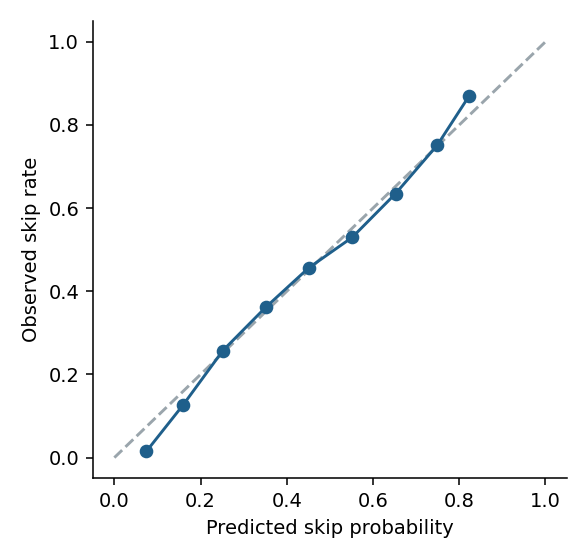

In [8]:
err = load('05_error_analysis', 'error_analysis.json')
print('Keys:', list(err))
display(Image(filename=str(R('05_error_analysis') / 'calibration.png'), width=500))

## 7. If we change one thing (`python/07_extra_experiments/run_extra.py`)
Each row changes one thing in the final model and re-scores it on the same 15 development folds.

In [9]:
ex = load('07_extra_experiments', 'extra_experiments.json')
print('final model, development MAA:', round(ex['base']['mean_fold_maa'], 4), '| fold SD:', round(ex['base']['std_fold_maa'], 4))
pd.DataFrame([{'change': e['change'], 'MAA': e['mean_fold_maa'], 'change in MAA': e['delta_maa'], 'folds better (of 15)': e.get('paired', {}).get('folds_better')} for e in ex['experiments']])

final model, development MAA: 0.5823 | fold SD: 0.0055


,change,MAA,change in MAA,folds better (of 15)
0,Drop the audio and metadata features,0.5828,4.6578e-04,11.0
1,Drop the similarity features,0.5813,-1.0274e-03,6.0
2,Drop the popularity features,0.5825,1.6059e-04,7.0
3,"Drop the start/end reason shares (rs_*, re_*)",0.5800,-2.2964e-03,2.0
4,Add skip_1 / skip_3 history features,0.5821,-1.8895e-04,7.0
5,Add per-session audio deltas (song minus first...,0.5823,-2.8614e-05,7.0
6,Add a per-song skip rate from other sessions,0.5804,-1.8618e-03,2.0
7,Replace LightGBM by logistic regression (popul...,0.5650,-1.7256e-02,0.0
8,First half = floor(L/2) instead of ceil(L/2),0.5776,-4.6725e-03,NaN


In [10]:
th = ex['threshold']
print('threshold 0.50 -> %.2f: MAA %.4f -> %.4f (gain %+.4f); chosen threshold %.2f' % (th['best'], th['maa_at_0.5'], th['maa_at_best'], th['gain'], th['chosen']))

threshold 0.50 -> 0.50: MAA 0.5840 -> 0.5840 (gain +0.0000); chosen threshold 0.50
